In [10]:
import os
data_path = '../../data/'

# List all CSV files
csv_files = [f for f in os.listdir(data_path) if f.endswith('.csv')]
print("CSV files found:", csv_files)

# Try loading with encoding
print("Loading UNSW-NB15 training data...", end=" ")
df_train = pd.read_csv(os.path.join(data_path, 'UNSW_NB15_training-set.csv'), encoding='latin-1')
print(f"✅ Shape: {df_train.shape}")

print("Loading UNSW-NB15 testing data...", end=" ")
df_test = pd.read_csv(os.path.join(data_path, 'UNSW_NB15_testing-set.csv'), encoding='latin-1')
print(f"✅ Shape: {df_test.shape}")

# Combine
df = pd.concat([df_train, df_test], ignore_index=True)
print(f"\n📊 Combined dataset shape: {df.shape}")
print(f"Total rows: {len(df):,}")

CSV files found: ['NUSW-NB15_features.csv', 'UNSW_NB15_testing-set.csv', 'UNSW_NB15_training-set.csv']
Loading UNSW-NB15 training data... ✅ Shape: (82332, 45)
Loading UNSW-NB15 testing data... ✅ Shape: (175341, 45)

📊 Combined dataset shape: (257673, 45)
Total rows: 257,673


In [11]:
# ==============================================
# 2. DATA EXPLORATION & QUALITY CHECKS
# ==============================================

print("Data Info:")
print(df.info())

print("\n" + "="*80)
print("Missing Values:")
print(df.isnull().sum())

print("\n" + "="*80)
print("Statistical Summary:")
print(df.describe())

print("\n" + "="*80)
print("Target Variable (label) Distribution:")
print(df['label'].value_counts())

Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 257673 entries, 0 to 257672
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   ï»¿id              257673 non-null  int64  
 1   dur                257673 non-null  float64
 2   proto              257673 non-null  str    
 3   service            257673 non-null  str    
 4   state              257673 non-null  str    
 5   spkts              257673 non-null  int64  
 6   dpkts              257673 non-null  int64  
 7   sbytes             257673 non-null  int64  
 8   dbytes             257673 non-null  int64  
 9   rate               257673 non-null  float64
 10  sttl               257673 non-null  int64  
 11  dttl               257673 non-null  int64  
 12  sload              257673 non-null  float64
 13  dload              257673 non-null  float64
 14  sloss              257673 non-null  int64  
 15  dloss              257673 non-null  int64  
 16  si

In [12]:
# ==============================================
# Check for Outliers, Duplicates, and Data Quality
# ==============================================

print("1. DUPLICATES CHECK:")
print(f"Total duplicate rows: {df.duplicated().sum()}")
print(f"Percentage: {df.duplicated().sum() / len(df) * 100:.2f}%")

print("\n2. INFINITE VALUES CHECK:")
print(f"Total infinite values: {np.isinf(df.select_dtypes(include=[np.number])).sum().sum()}")

print("\n3. DATA TYPES:")
print(df.dtypes)

print("\n4. TARGET VARIABLE DISTRIBUTION:")
print(df['label'].value_counts())
print("\nClass Distribution (%):")
print((df['label'].value_counts() / len(df) * 100).round(2))

print("\n5. OUTLIERS CHECK (using IQR method on first numeric column):")
numeric_cols = df.select_dtypes(include=[np.number]).columns
if len(numeric_cols) > 0:
    col = numeric_cols[0]
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df[(df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)]
    print(f"Column: {col}")
    print(f"Outliers found: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")

1. DUPLICATES CHECK:
Total duplicate rows: 0
Percentage: 0.00%

2. INFINITE VALUES CHECK:
Total infinite values: 0

3. DATA TYPES:
ï»¿id                  int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64

In [13]:
# Fix BOM issue and reload
print("Loading with BOM fix...", end=" ")
df_train = pd.read_csv('../../data/UNSW_NB15_training-set.csv', encoding='utf-8-sig')
df_test = pd.read_csv('../../data/UNSW_NB15_testing-set.csv', encoding='utf-8-sig')
df = pd.concat([df_train, df_test], ignore_index=True)
print(f"✅ Shape: {df.shape}")

print("\nColumn names after BOM fix:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Loading with BOM fix... ✅ Shape: (257673, 45)

Column names after BOM fix:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Data types:
id                     int64
dur                  float64
proto                    str
service                  str
state                    str
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload             

In [14]:
# ==============================================
# 3. PREPROCESSING: HANDLE CATEGORICAL VARIABLES
# ==============================================

from sklearn.preprocessing import LabelEncoder

# Identify categorical columns
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"Categorical columns: {categorical_cols}")

# Display unique values
for col in categorical_cols:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts())

Categorical columns: ['proto', 'service', 'state', 'attack_cat']

proto: 133 unique values
proto
tcp       123041
udp        92701
unas       15599
arp         3846
ospf        3271
           ...  
netblt       131
crtp         131
igmp          48
icmp          15
rtp            1
Name: count, Length: 133, dtype: int64

service: 13 unique values
service
-           141321
dns          68661
http         27011
smtp          6909
ftp-data      5391
ftp           4980
pop3          1528
ssh           1506
dhcp           120
snmp           109
ssl             86
irc             30
radius          21
Name: count, dtype: int64

state: 11 unique values
state
FIN    117164
INT    116438
CON     20134
REQ      3833
RST        84
ECO        12
ACC         4
CLO         1
PAR         1
URN         1
no          1
Name: count, dtype: int64

attack_cat: 10 unique values
attack_cat
Normal            93000
Generic           58871
Exploits          44525
Fuzzers           24246
DoS               163

In [15]:
# ==============================================
# ENCODE CATEGORICAL VARIABLES
# ==============================================

from sklearn.preprocessing import LabelEncoder

# Create a copy for preprocessing
df_processed = df.copy()

# Encode categorical columns
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_processed[col] = le.fit_transform(df_processed[col].astype(str))
    label_encoders[col] = le
    print(f"✅ Encoded {col}: {len(le.classes_)} unique values")

print("\n" + "="*80)
print("Data types after encoding:")
print(df_processed.dtypes)

print("\n" + "="*80)
print("Sample of encoded data:")
print(df_processed.head())

✅ Encoded proto: 133 unique values
✅ Encoded service: 13 unique values
✅ Encoded state: 11 unique values
✅ Encoded attack_cat: 10 unique values

Data types after encoding:
id                     int64
dur                  float64
proto                  int64
service                int64
state                  int64
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean           

Class Distribution:
label
1    164673
0     93000
Name: count, dtype: int64

Percentage:
label
1    63.91
0    36.09
Name: count, dtype: float64


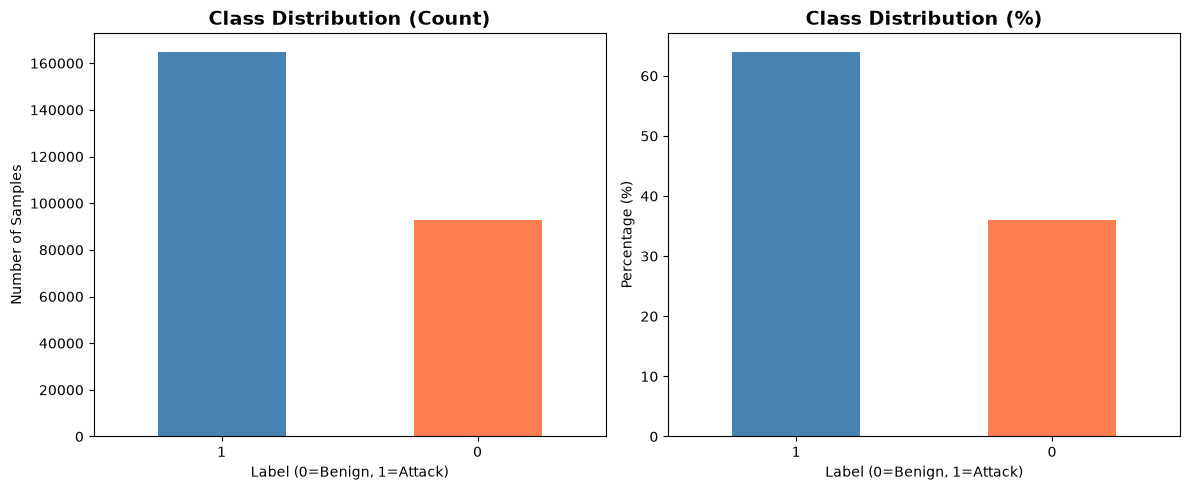


✅ Visualization saved!


In [16]:
# ==============================================
# CLASS IMBALANCE ANALYSIS & VISUALIZATION
# ==============================================

# Check class distribution
print("Class Distribution:")
print(df_processed['label'].value_counts())
print("\nPercentage:")
print((df_processed['label'].value_counts() / len(df_processed) * 100).round(2))

# Visualize
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
df_processed['label'].value_counts().plot(kind='bar', color=['steelblue', 'coral'])
plt.title('Class Distribution (Count)', fontsize=14, fontweight='bold')
plt.xlabel('Label (0=Benign, 1=Attack)')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
(df_processed['label'].value_counts() / len(df_processed) * 100).plot(kind='bar', color=['steelblue', 'coral'])
plt.title('Class Distribution (%)', fontsize=14, fontweight='bold')
plt.xlabel('Label (0=Benign, 1=Attack)')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig('../../data/02_class_imbalance.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Visualization saved!")

In [17]:
# ==============================================
# PHASE 3 SUMMARY
# ==============================================

print("="*80)
print("PHASE 3: PREPROCESSING COMPLETE")
print("="*80)

print("\n✅ DATA QUALITY CHECKS:")
print(f"  - No missing values: {df_processed.isnull().sum().sum() == 0}")
print(f"  - No duplicates: {df_processed.duplicated().sum() == 0}")
print(f"  - No infinite values: {np.isinf(df_processed.select_dtypes(include=[np.number])).sum().sum() == 0}")

print("\n✅ PREPROCESSING COMPLETED:")
print(f"  - Encoded categorical variables: {len(categorical_cols)} columns")
print(f"  - All features now numeric: {df_processed.select_dtypes(include=[np.number]).shape[1]} columns")

print("\n✅ CLASS IMBALANCE IDENTIFIED:")
print(f"  - Benign (0): {(df_processed['label'] == 0).sum():,} samples (36.09%)")
print(f"  - Attack (1): {(df_processed['label'] == 1).sum():,} samples (63.91%)")
print(f"  - Imbalance Ratio: 1.77:1")

print("\n✅ READY FOR PHASE 4: MODEL TRAINING")
print(f"  - Total samples: {len(df_processed):,}")
print(f"  - Total features: {df_processed.shape[1]}")
print(f"  - Data shape: {df_processed.shape}")

print("\n" + "="*80)

PHASE 3: PREPROCESSING COMPLETE

✅ DATA QUALITY CHECKS:
  - No missing values: True
  - No duplicates: True
  - No infinite values: True

✅ PREPROCESSING COMPLETED:
  - Encoded categorical variables: 4 columns
  - All features now numeric: 45 columns

✅ CLASS IMBALANCE IDENTIFIED:
  - Benign (0): 93,000 samples (36.09%)
  - Attack (1): 164,673 samples (63.91%)
  - Imbalance Ratio: 1.77:1

✅ READY FOR PHASE 4: MODEL TRAINING
  - Total samples: 257,673
  - Total features: 45
  - Data shape: (257673, 45)

